## Lab 4: Working with 'real' data


In [98]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py


# getting data
hf = h5py.File('gammaray_lab4.h5', 'r')
hf.keys()
data = np.array(hf.get('data'))
np.shape(data)
hf.close()


### Problem

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

1. Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

2. The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

3. Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

4. Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

5. While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

### 1. Various plots of data


#### 1.a) plotting counts vs time

degree of earth longitude where values spike 315.3333333333333
phase between degree of earth and spike in higher counts 270.3333333333333


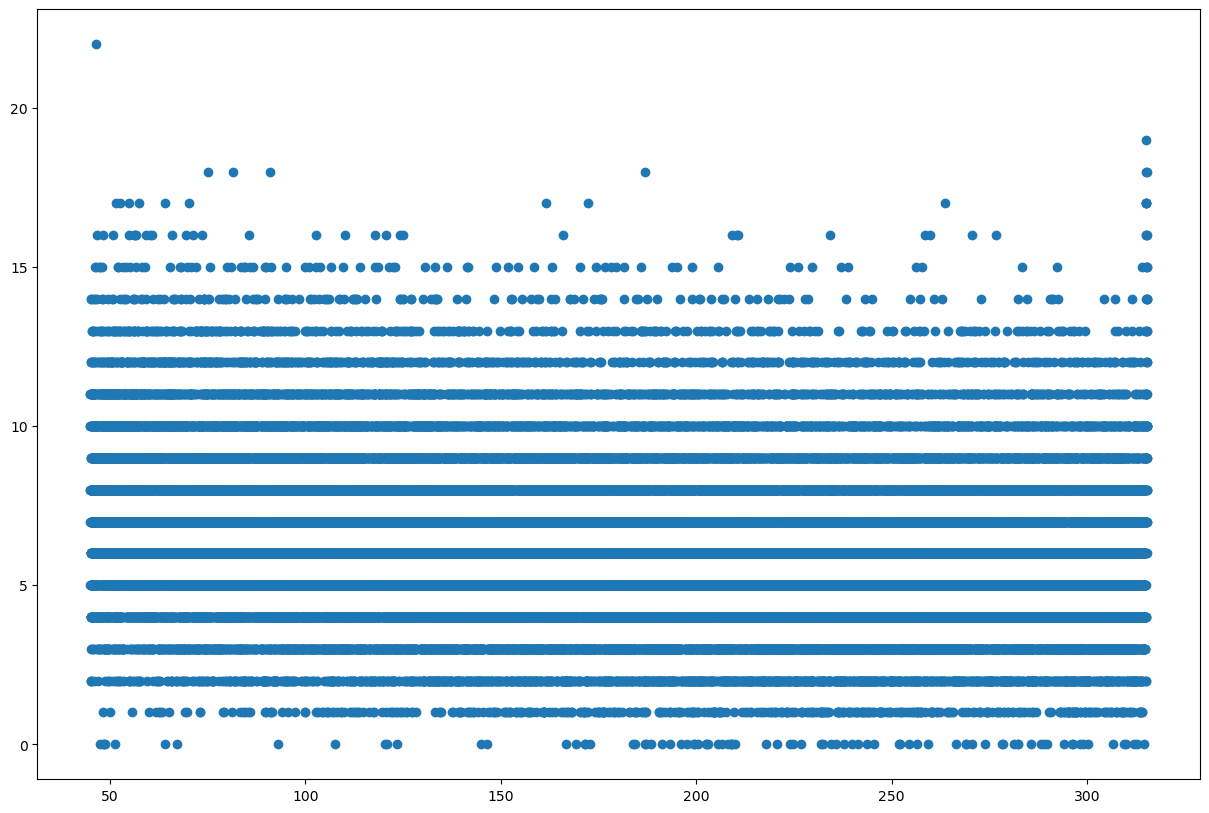

In [99]:
# scatter plot of counts vs time

plt.rcParams["figure.figsize"] = (15,10)

idx = 40550
spike_deg = data[2][idx] # looking at plot to choose idx where spike in counts per measurement occur
spike_phase = data[2][idx] - data[2][0]

print(f"degree of earth longitude where values spike {spike_deg}")
print(f"phase between degree of earth and spike in higher counts {spike_phase}")

t = data[2][0:idx]

counts = data[3][0:idx]

fig, ax = plt.subplots(1, 1)
plt.scatter(t, counts)

plt.show()

#### 1.b Counts vs Orbital Period (folded 5 periods to get single period) at beginning and middle of data

The minimum mean count is 5.664444444444444 and the maximum mean count is 11.365925925925925


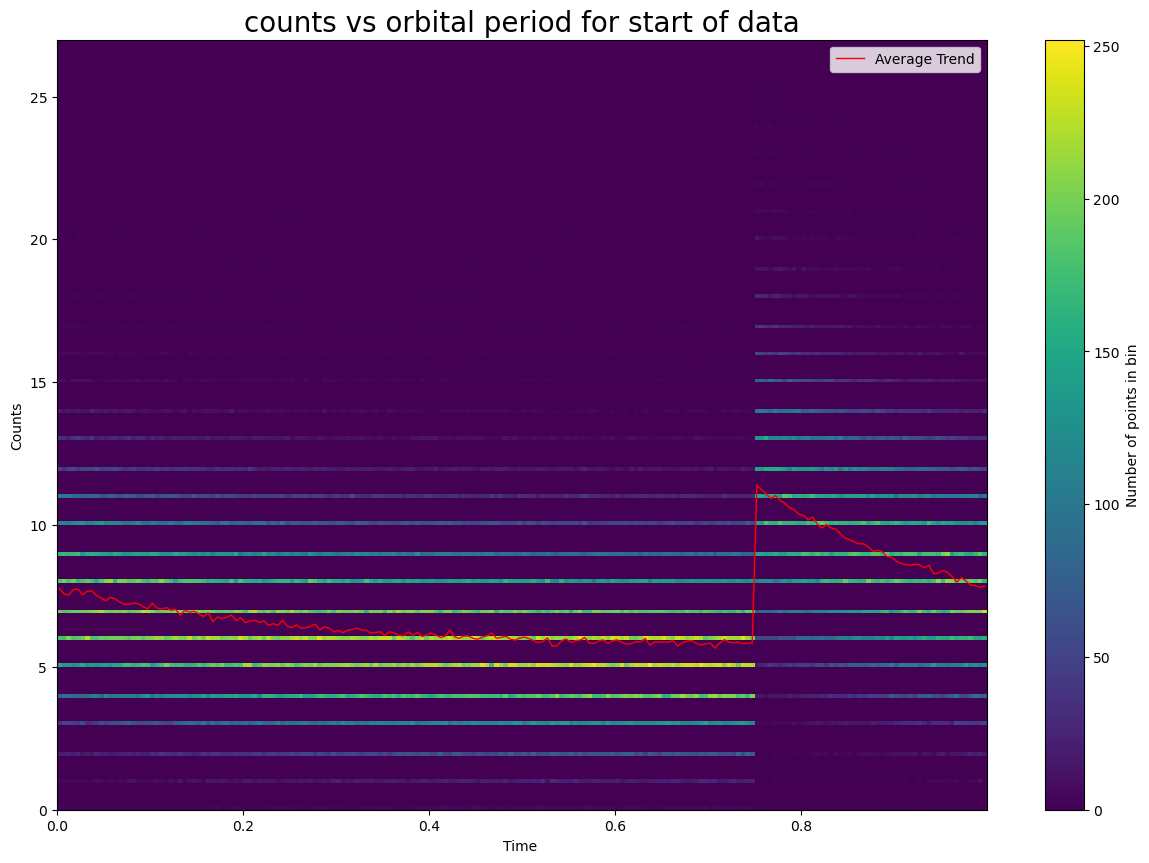

The minimum mean count is 5.706666666666667 and the maximum mean count is 11.375555555555556


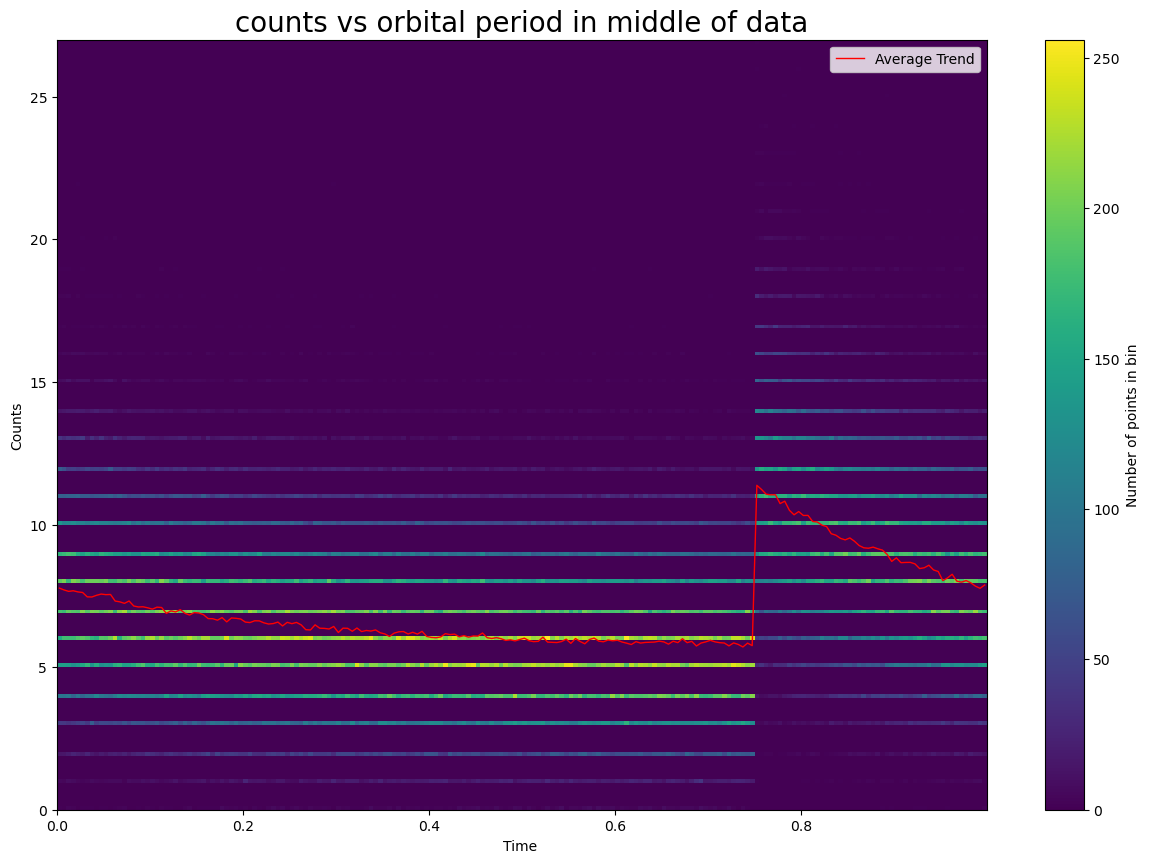

In [100]:

# 2d histogram plot of counts vs orbital period for first 5 orbits folded into 1 period

plt.rcParams["figure.figsize"] = (15,10)

idx_5_orbits = 90*60*10*5

t_5_orbits = data[0][0:idx_5_orbits] - data[0][0]

counts = data[3][0:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

# Finding minimum and maximum mean counts
bin_min = np.min(bin_means)
bin_max = np.max(bin_means)
print(f"The minimum mean count is {bin_min} and the maximum mean count is {bin_max}")


bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period for start of data',  fontsize = 20)
ax.legend(loc='upper right')
plt.show()

# scatter plot of counts vs orbital period for 5 orbits halfway into the data

start_idx = data.shape[1] // 2

idx_5_orbits = 90*60*10*5 + start_idx

t_5_orbits = data[0][start_idx:idx_5_orbits] - data[0][start_idx]

counts = data[3][start_idx:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

# Finding minimum and maximum mean counts
bin_min = np.min(bin_means)
bin_max = np.max(bin_means)
print(f"The minimum mean count is {bin_min} and the maximum mean count is {bin_max}")

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period in middle of data', fontsize = 20)
ax.legend(loc='upper right')
plt.show()

#### 1.c) 2D Histogram Plot of counts over 5 orbital periods (halfway into data)

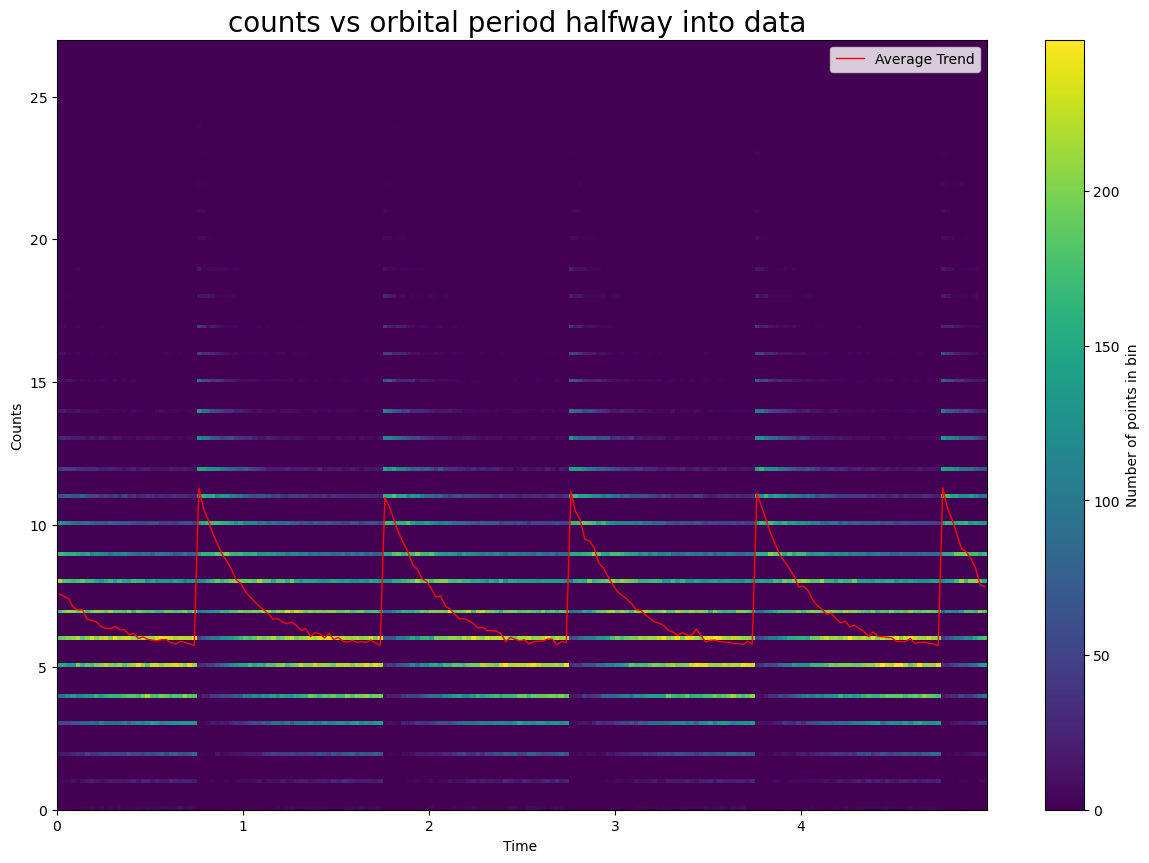

In [101]:
# scatter plot of counts vs orbital period for 5 orbits halfway in the data

start_idx = data.shape[1] // 2

idx_5_orbits = 90*60*10*5 + start_idx

t_5_orbits = data[0][start_idx:idx_5_orbits] - data[0][start_idx]

counts = data[3][start_idx:idx_5_orbits]

t_orbit_folded = (t_5_orbits / (60*90) % 5)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Time ')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period halfway into data ',  fontsize = 20)
ax.legend(loc='upper right')
plt.show()

#### 1.d) 2d histogram plot of counts vs solar phase (which tends to average out with phase)

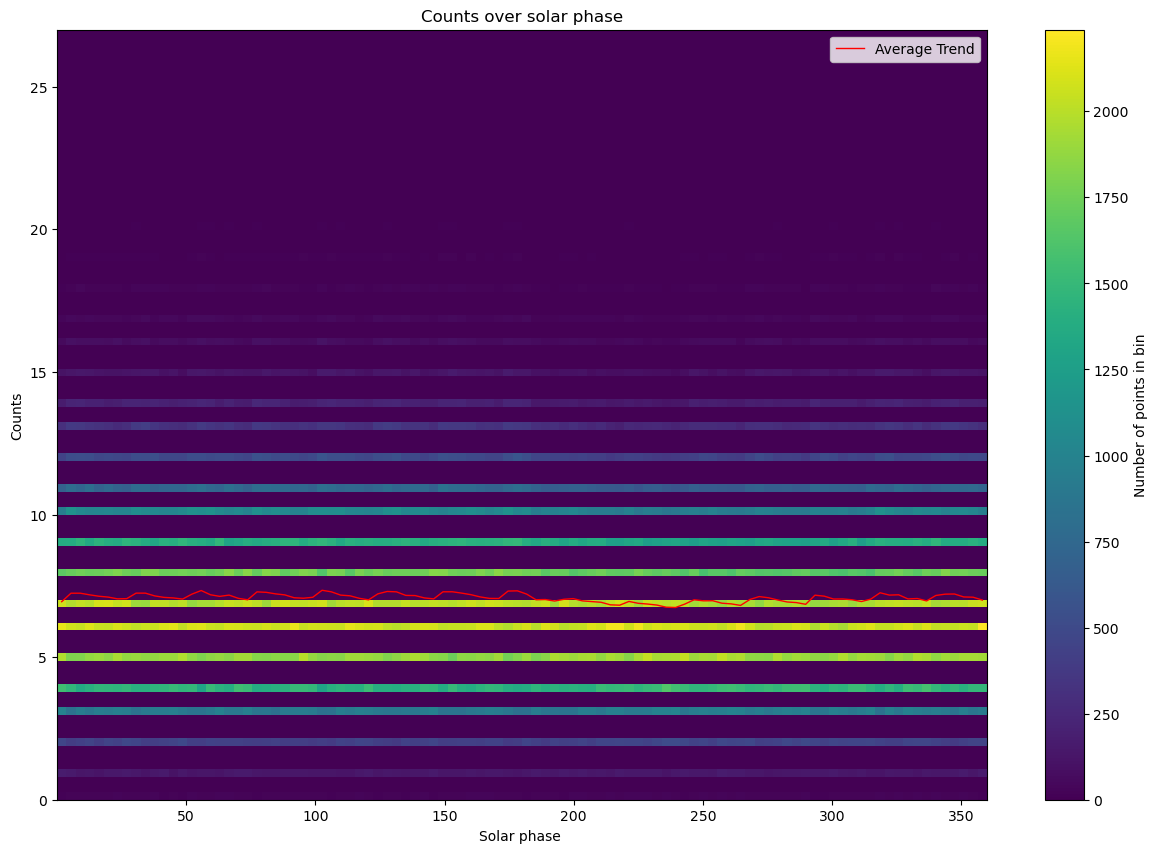

In [102]:
# 2d histogram plot of counts vs solar phase

start_idx = 0
idx_solar = 50000*30 + start_idx

solar_phase = data[1][start_idx:idx_solar]

counts = data[3][start_idx:idx_solar]

# --- 2D Histogram Plot of counts vs time ---
num_bins = 100

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(solar_phase, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    solar_phase, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Solar phase ')
ax.set_ylabel('Counts')
ax.set_title('Counts over solar phase')
ax.legend(loc='upper right')
plt.show()


When comparing data over numerous solar phases, the effect of the phase appears to average out.

#### 1.e) 2d histogram plot of counts vs earth longitude in degrees (many periods of data and then 1 period plot shown)

The minimum mean count is 5.607407407407408 and the maximum mean count is 10.933333333333334


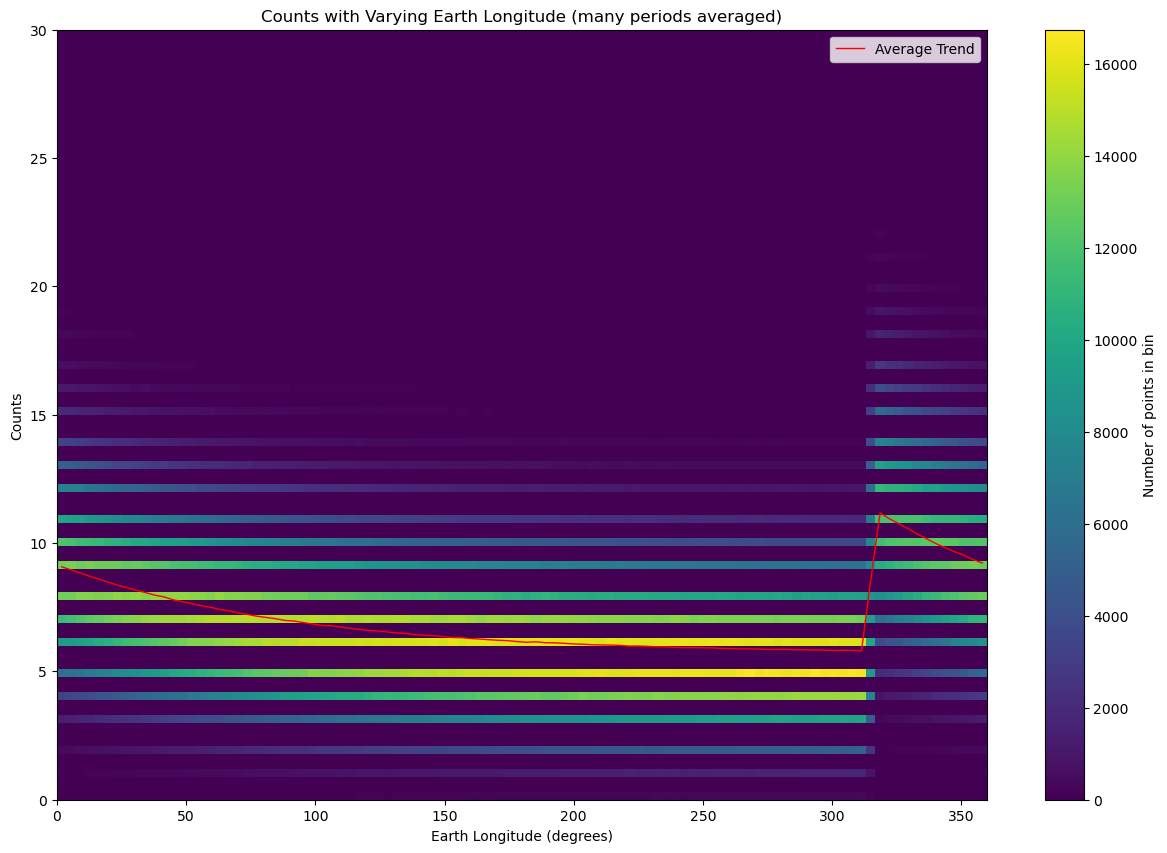

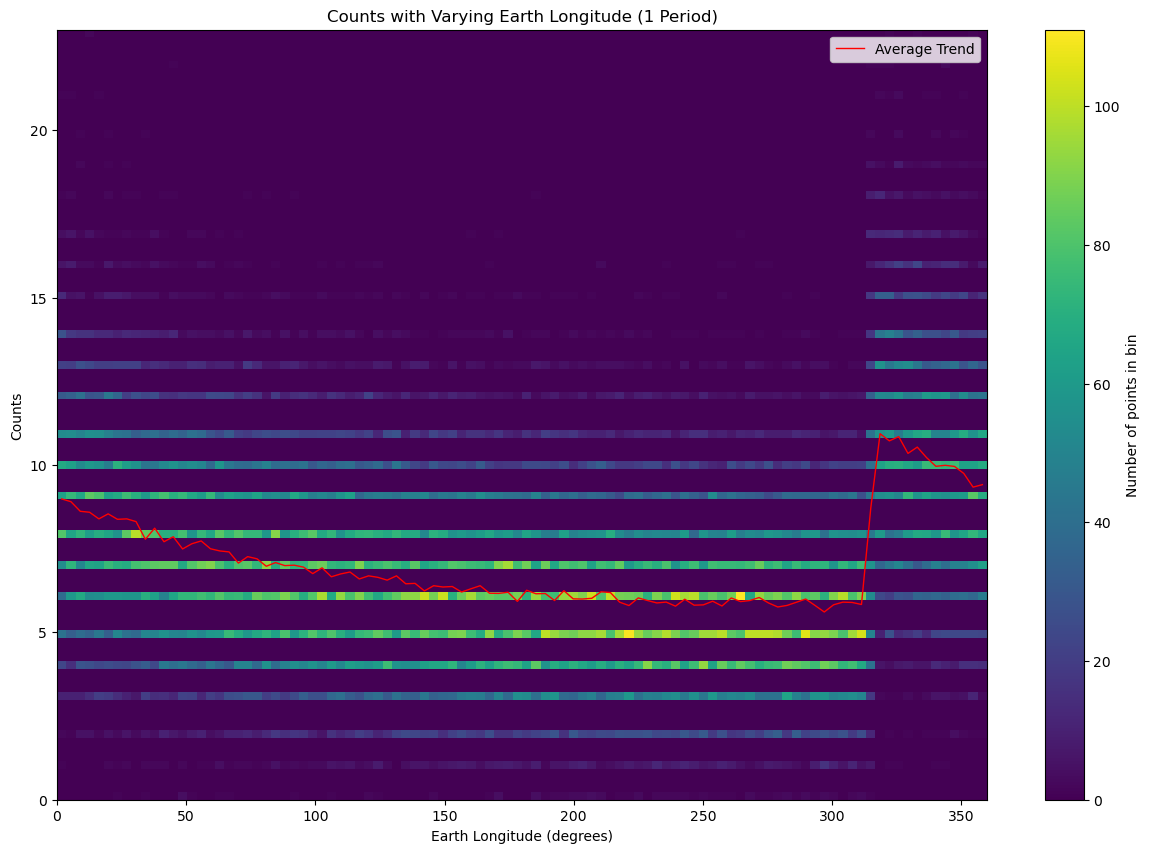

In [103]:

# 2d histogram plot of counts vs earth longitude in degrees; many periods of data

start_idx = 0
idx_end = 10000000 + start_idx

earth_longitude = data[2][start_idx:idx_end]

counts = data[3][start_idx:idx_end]

# --- 2D Histogram Plot of counts vs time ---
num_bins = 100

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(earth_longitude, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    earth_longitude, counts, statistic='mean', bins=num_bins
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Plotting
ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Earth Longitude (degrees)')
ax.set_ylabel('Counts')
ax.set_title('Counts with Varying Earth Longitude (many periods averaged)')
ax.legend(loc='upper right')

# 2d histogram plot of counts vs earth longitude in degrees (1 period of data)

start_idx = 0
idx_end = 54000 + start_idx

earth_longitude = data[2][start_idx:idx_end]

counts = data[3][start_idx:idx_end]

# --- 2D Histogram Plot of counts vs time ---
num_bins = 100

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(earth_longitude, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    earth_longitude, counts, statistic='mean', bins=num_bins
)


bin_min = np.min(bin_means)
bin_max = np.max(bin_means)

print(f"The minimum mean count is {bin_min} and the maximum mean count is {bin_max}")

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Plotting
ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Earth Longitude (degrees)')
ax.set_ylabel('Counts')
ax.set_title('Counts with Varying Earth Longitude (1 Period)')
ax.legend(loc='upper right')

plt.show()

#### 1.f) Histogram plot of distribution of average counts using small section of each period from the data

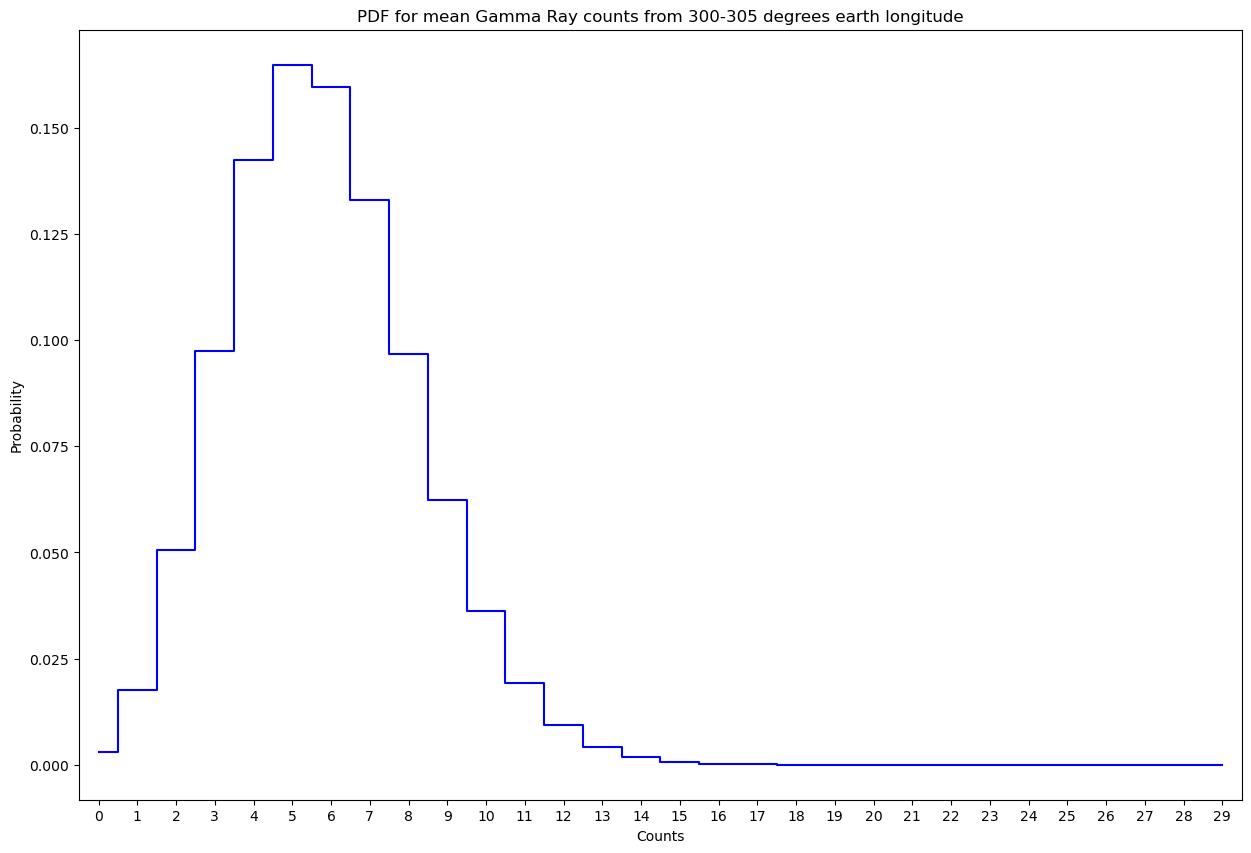

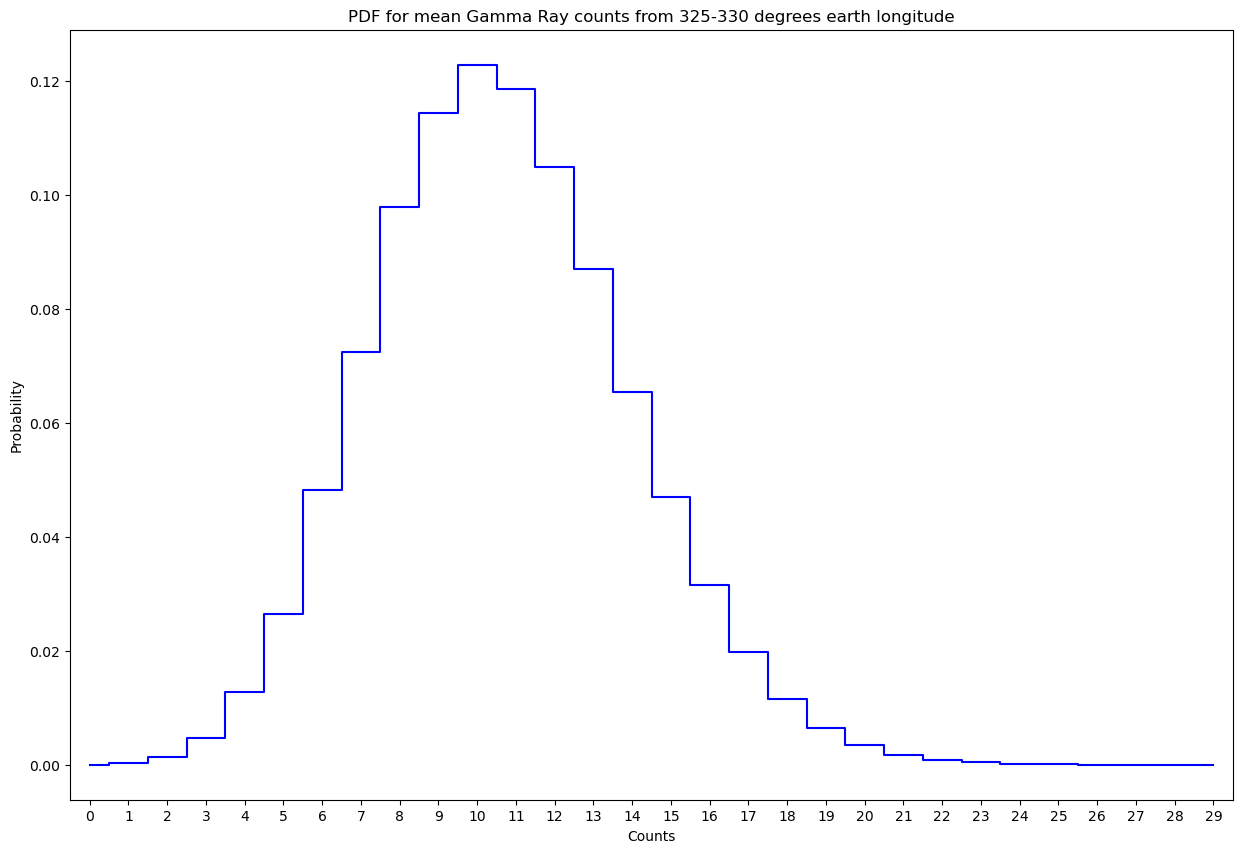

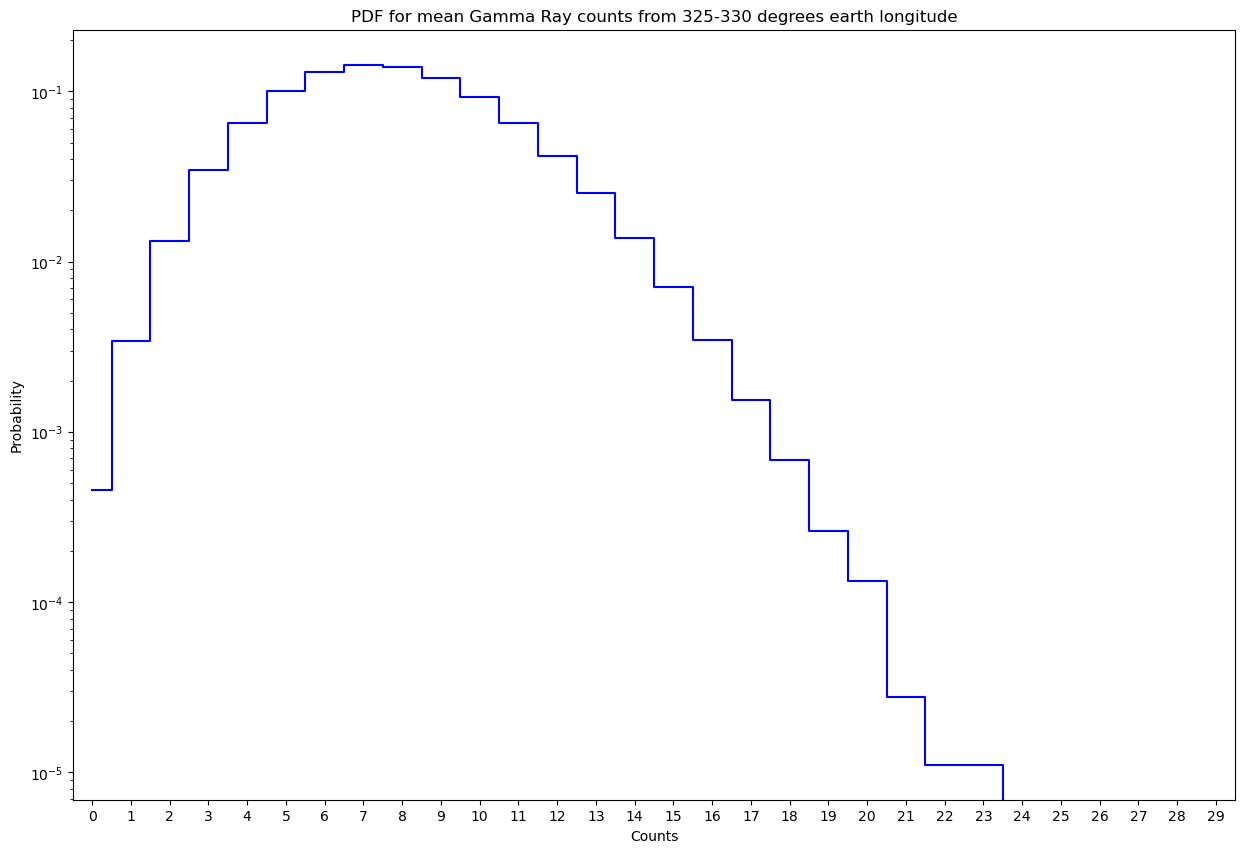

In [104]:
# Histogram of data for same orbital degree ( first 300 to 305 degrees)

lon_start = 300
lon_end = 305

earth_longitude = data[2]
counts = data[3]

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
)

ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
ax.set_xlabel('Counts')
ax.set_ylabel('Probability')
ax.set_title('PDF for mean Gamma Ray counts from 300-305 degrees earth longitude')

# Now doing the same as above except at 325 degrees
lon_start = 325
lon_end = 330

earth_longitude = data[2]
counts = data[3]

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
)


ax.set_xlabel('Counts')
ax.set_ylabel('Probability')
ax.set_title('PDF for mean Gamma Ray counts from 325-330 degrees earth longitude')
ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
plt.show()

# Now doing the same as above except at start of data
lon_start = data[2][0]
lon_end = lon_start + 5

earth_longitude = data[2]
counts = data[3]

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
)

ax.set_yscale('log')
ax.set_xlabel('Counts')
ax.set_ylabel('Probability')
ax.set_title('PDF for mean Gamma Ray counts from 325-330 degrees earth longitude')
ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
plt.show()


#### 1. 

Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

#### Response to 1:

Features:

The distribution of the data appears mostly associated with the earth longitude degree. Looking at the data plotted using a 2D histogram with respect to the time (or the earth longitude), the probability distribution for counts appears to repeat with each orbital period (equivalently, with each 360 degree change to the longitude) where the mean count value decays exponentially and then is reset with each orbital period. This provides a stable feature that when used to average over, provides a very smooth non-trivial curve that decays exponentially. Note that when averaging, the reset is less abrupt due to shifts in the reset degree, possibly because the 90 minute orbital period is not exact. Moving to the data when averaged over the solar phase, it appears to mostly average out as more cycles are averaged over, so there appears to be not much interesting there besides the fact that there appears to always be a background of some average rate of counts detected. When looking at the probability distributions over the same earth longitude (or rather averaging counts near the same longitude, I used a 5 degree period) the pdf is discrete and resembles a poisson distribution. 

Signal contamination: 

There are not any counts (within a given 100 ms measurement period) greater than 30 in the data. So if we expect a GRB that is not from the background, it is either less than 30 minus whatever background GRB counts there were, or there are no signal like GRB. In either case, the background pdf shifts with time, so what would be considered signal varies as well. Near the start of the data, there is a possible candidate for a signal as over 20 counts are measured when such a value appears very rare for similar earth longitude counts measured.

How to build background PDF:

The background appears to be well described by a poisson distribution with some average rate that changes over the orbital period. So we could build a pdf by finding the average number of counts at the minimum and maximum mean counts across the orbital period, and then use this average in a model Poisson distribution that displays a mean count rate that decays exponentially with each orbit and then resets. We would need to characterize the decay of the exponential by finding the point at which the exponentially decaying contribution decays to 1/2 its maximum value (by looking at the 2D histogram and finding where the mean count falls to 1/2 maximum mean from decay + background constant mean for example). Our model ignores the fact the decay would bring the minimum value lower, so fitting is done imprecisely, but could be done if more points are taken to better fit the curve shown in section 1.e)



#### 2.
The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

Answer: The background changes with the orbital period. The mean number of counts for a small travel time of the telescope exponentially decays over the orbital period and then resets very quickly. The maximum mean is around 11 counts while the minimum mean is around 6 counts over the whole period, and this does not appear to change much over the range of data. 



#### 3. 
Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

Creating Model: 
First we consider the data has a mean that exponentially decays over the orbital period before resetting to a maximum value. The maximum value we will consider is 11, and a minimum of 6. So the decaying exponential part is about a max amplitude of 5 while a stable background of around 6 is always added. The decaying exponential part resets with each orbital period, where the maximum of the mean number of counts calculated occurs at about 315 degrees earth longitude. 


In [259]:
# Creating Model:
n_periods = 20 # 10 periods to save on computation
start_time = data[0][0] # same start time as data used
end_time = data[0][90*60*10*n_periods]
n_points = 90*60*10 * n_periods

time = np.linspace(start_time, end_time, n_points)

# creating model
def get_model_background_data(time):
    data_model = np.empty((3,len(time)))
    for i in np.arange(len(time)):
        phase = ((((time[i] - data[0][0])* 360 / (60*90) + data[2][0])  % 360)) # converting to phase, time or orbital period could also be used
        mu = 5.7 + 5.6 * np.e**(-.01100 * ((phase - 315.15) % 360)) # value of .0150 estimated based on 1/2 exponential value being at around 65 degrees
        model_bkgd_point = stats.poisson.rvs(mu, loc=0, size=1, random_state=None)[0]
        data_model[0][i] = time[i] # adding time t to data for model
        data_model[1][i] = model_bkgd_point # adding background counts at time t to data for model
        data_model[2][i] = phase
    return data_model

data_model = get_model_background_data(time)


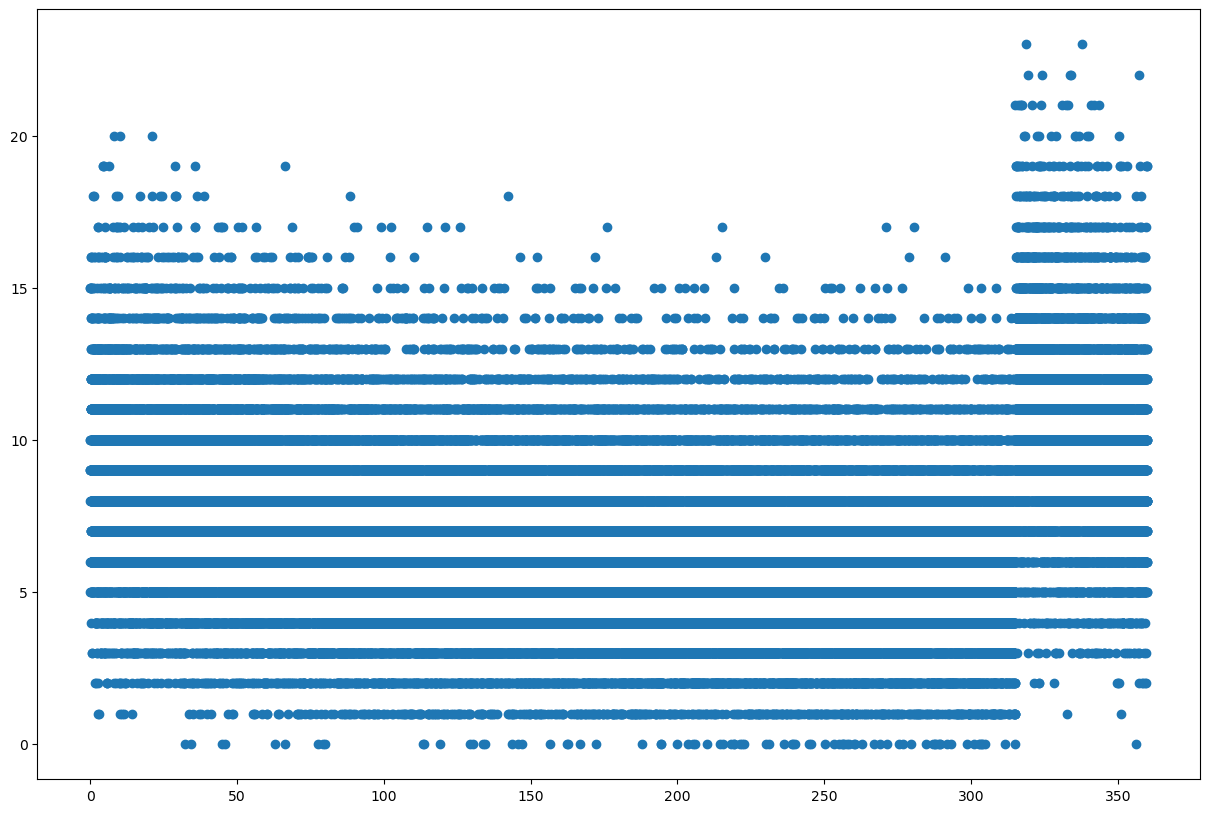

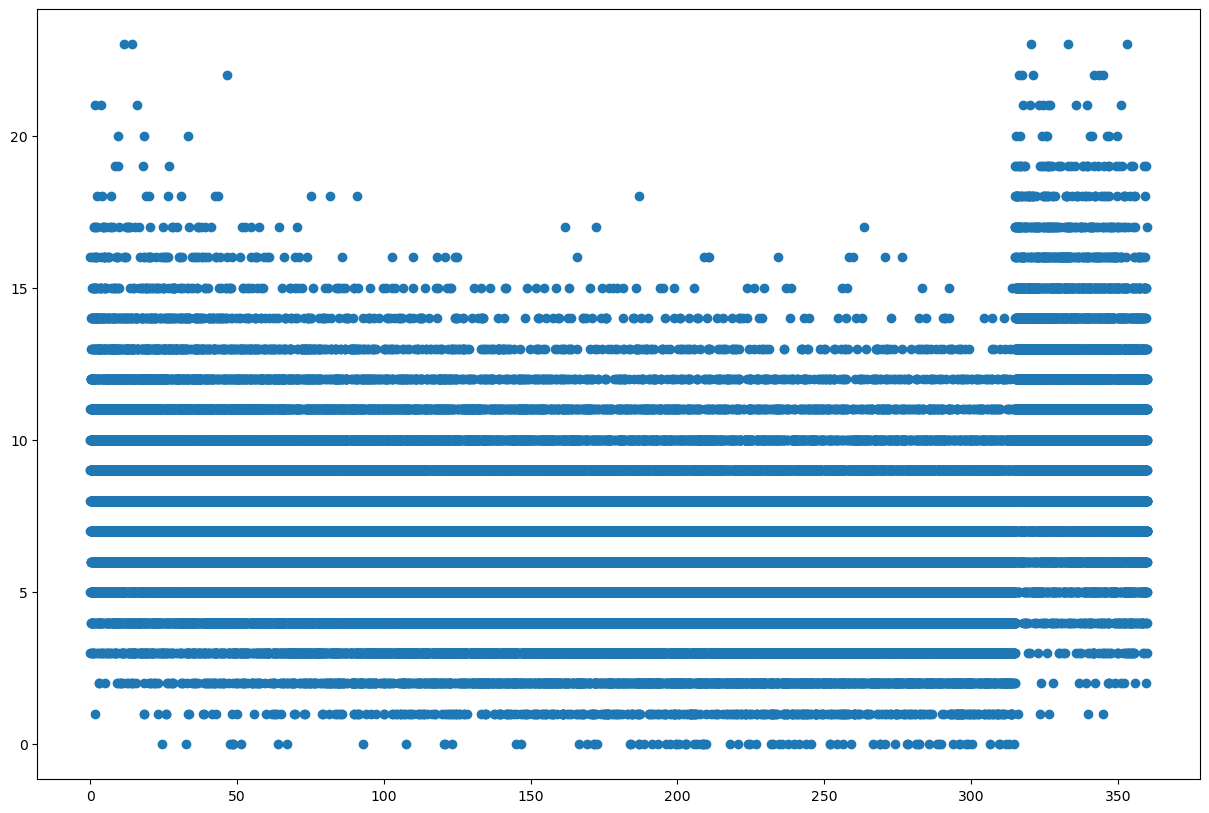

In [260]:
# plotting data from model
fig, ax = plt.subplots(1, 1)
plt.scatter(data_model[2][:90*60*10], data_model[1][:90*60*10])
plt.show()

# plotting real (simulated) data
fig, ax = plt.subplots(1, 1)
plt.scatter(data[2][:90*60*10], data[3][:90*60*10])
plt.show()

#### Comparing Model to Data:

first 2d histogram of model and then data (for 1 orbital period) is shown, then background distribution for narrow degree range is shown

The minimum mean count is 5.614814814814815 and the maximum mean count is 11.337037037037037
The minimum mean count is 5.514814814814815 and the maximum mean count is 11.537037037037036


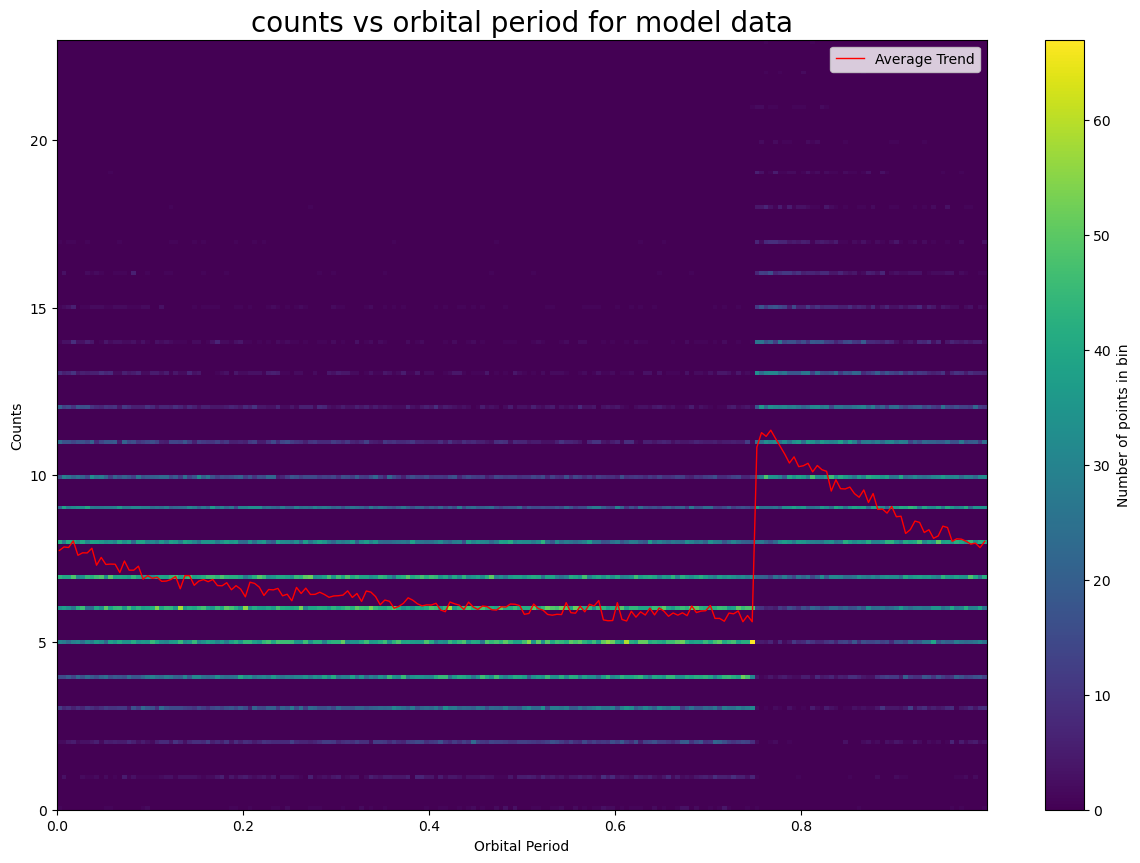

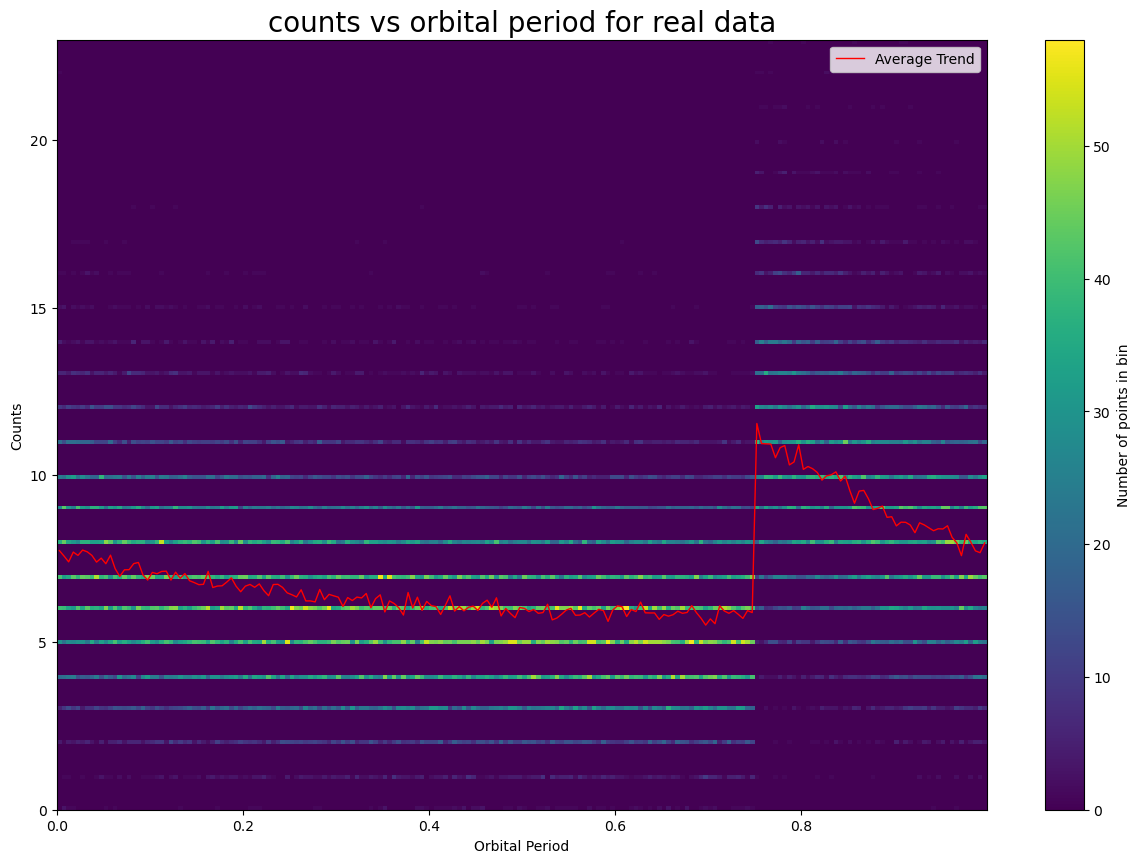

In [261]:

idx_1_orbits = 90*60*10
t_1_orbits = data_model[0][0:idx_1_orbits] - data_model[0][0]
counts = data_model[1][0:idx_1_orbits]
t_orbit_folded = (t_1_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

# Finding minimum and maximum mean counts
bin_min = np.min(bin_means)
bin_max = np.max(bin_means)
print(f"The minimum mean count is {bin_min} and the maximum mean count is {bin_max}")


bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Orbital Period')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period for model data', fontsize=20)
ax.legend(loc='upper right')

idx_1_orbits = 90*60*10
t_1_orbits = data[0][0:idx_1_orbits] - data[0][0]
counts = data[3][0:idx_1_orbits]
t_orbit_folded = (t_1_orbits / (60*90) % 1)

# --- 2D Histogram Plot of counts vs time ---
num_bins = 200

fig, ax = plt.subplots(1, 1)
hb = ax.hist2d(t_orbit_folded, counts, bins=num_bins, cmap='viridis')
fig.colorbar(hb[3], ax=ax, label='Number of points in bin')

bin_means, bin_edges, _ = stats.binned_statistic(
    t_orbit_folded, counts, statistic='mean', bins=num_bins
)

# Finding minimum and maximum mean counts
bin_min = np.min(bin_means)
bin_max = np.max(bin_means)
print(f"The minimum mean count is {bin_min} and the maximum mean count is {bin_max}")


bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

ax.plot(bin_centers, bin_means, color='red', linewidth=1.0, label='Average Trend')

ax.set_xlabel('Orbital Period')
ax.set_ylabel('Counts')
ax.set_title('counts vs orbital period for real data', fontsize=20)
ax.legend(loc='upper right')

plt.show()

45.0
[ 9. 12.  6. ...  7.  5.  4.]


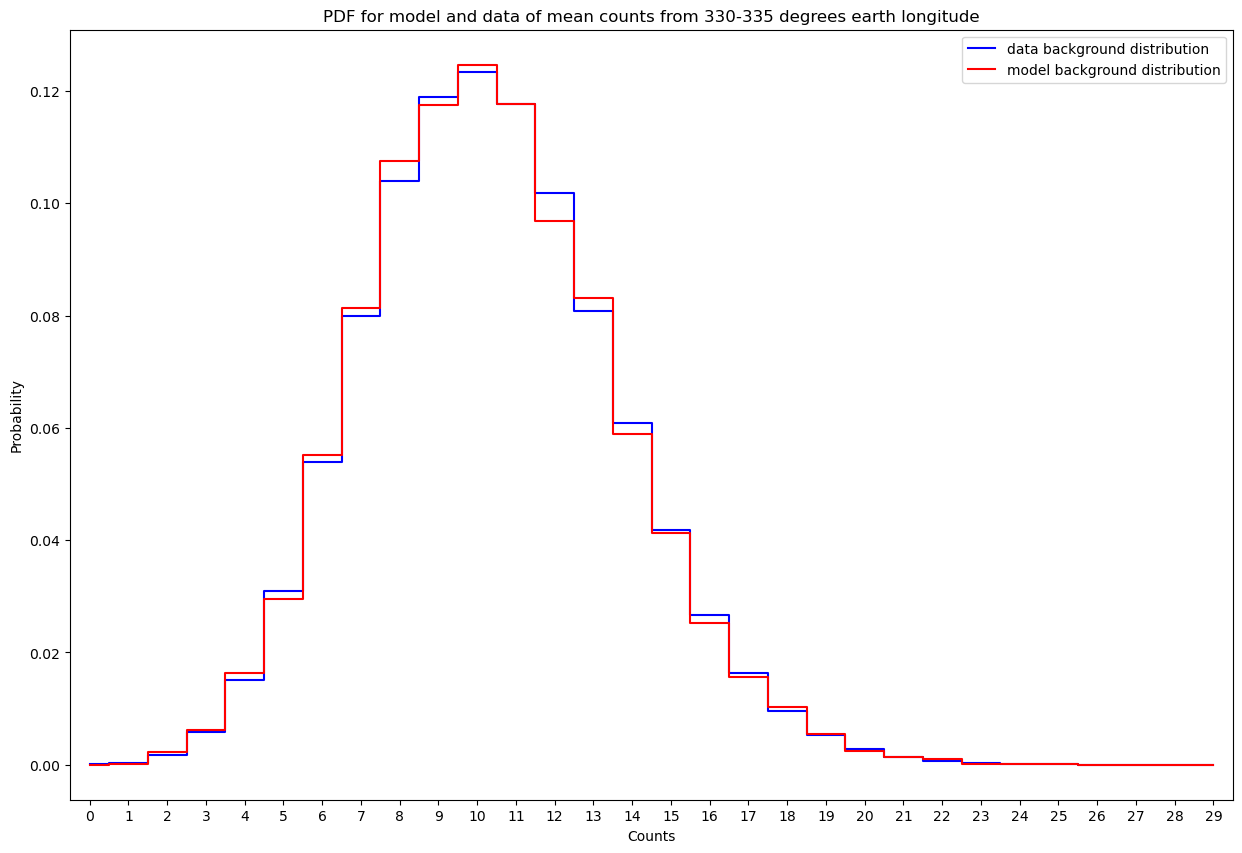

In [262]:
# Histogram of data for same orbital degree ( first 330-335 degrees)

lon_start = 330
lon_end = 335

earth_longitude = data[2]
counts = data[3]
print(data[2][0])

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
    label='data background distribution'
)

ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
ax.set_xlabel('Counts')
ax.set_ylabel('Probability')


# Histogram of model data for same orbital degree ( first 300 to 305 degrees)

lon_start = 330
lon_end = 335

earth_longitude = data_model[2]
counts = data_model[1]

print(data_model[1])

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='red',
    label='model background distribution'
)

ax.legend(loc='upper right')
ax.set_title('PDF for model and data of mean counts from 330-335 degrees earth longitude')

plt.show()

45.0
[ 9. 12.  6. ...  7.  5.  4.]


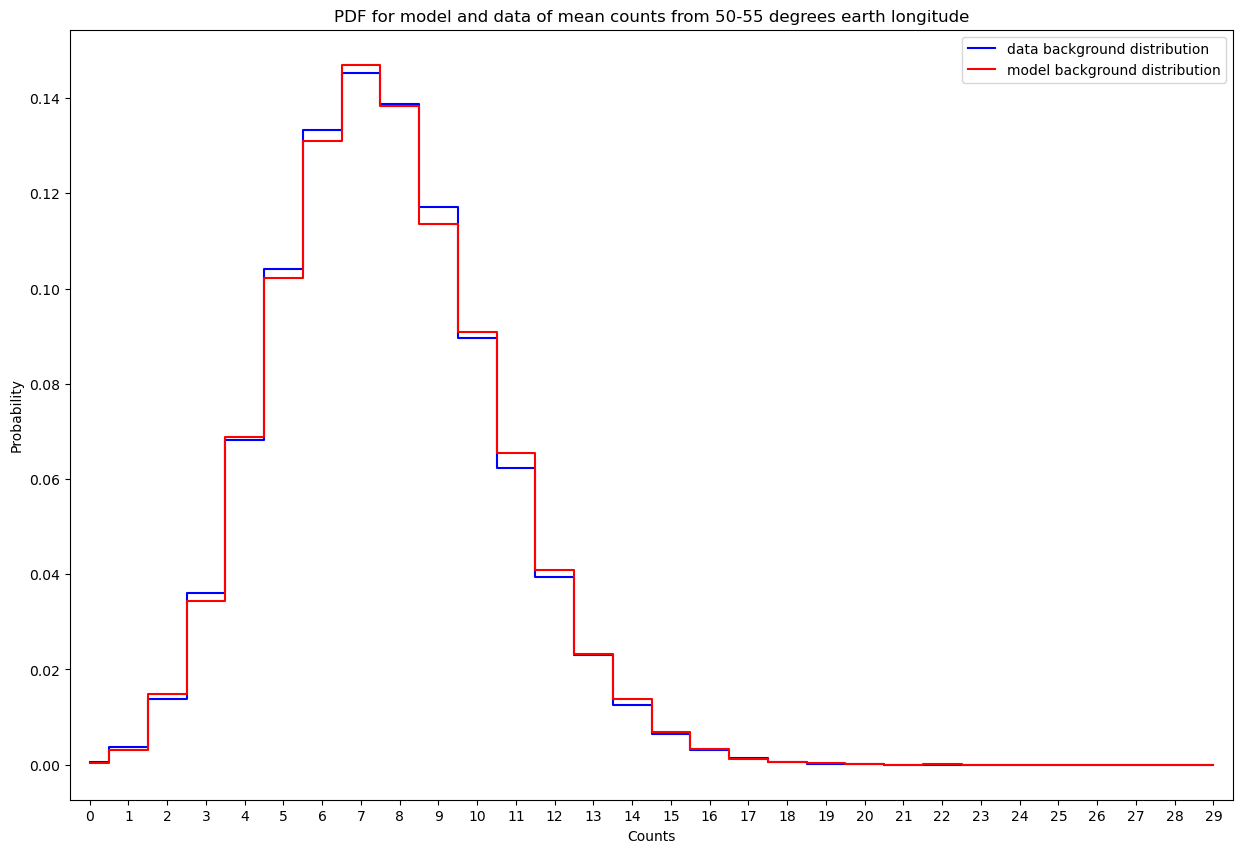

In [263]:
# Histogram of data for same orbital degree ( first 50-55 degrees)

lon_start = 50
lon_end = 55

earth_longitude = data[2]
counts = data[3]
print(data[2][0])

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
    label='data background distribution'
)

ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
ax.set_xlabel('Counts')
ax.set_ylabel('Probability')


# Histogram of model data for same orbital degree ( first 300 to 305 degrees)

lon_start = 50
lon_end = 55

earth_longitude = data_model[2]
counts = data_model[1]

print(data_model[1])

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='red',
    label='model background distribution'
)

ax.legend(loc='upper right')
ax.set_title('PDF for model and data of mean counts from 50-55 degrees earth longitude')

plt.show()

[ 9. 12.  6. ...  7.  5.  4.]


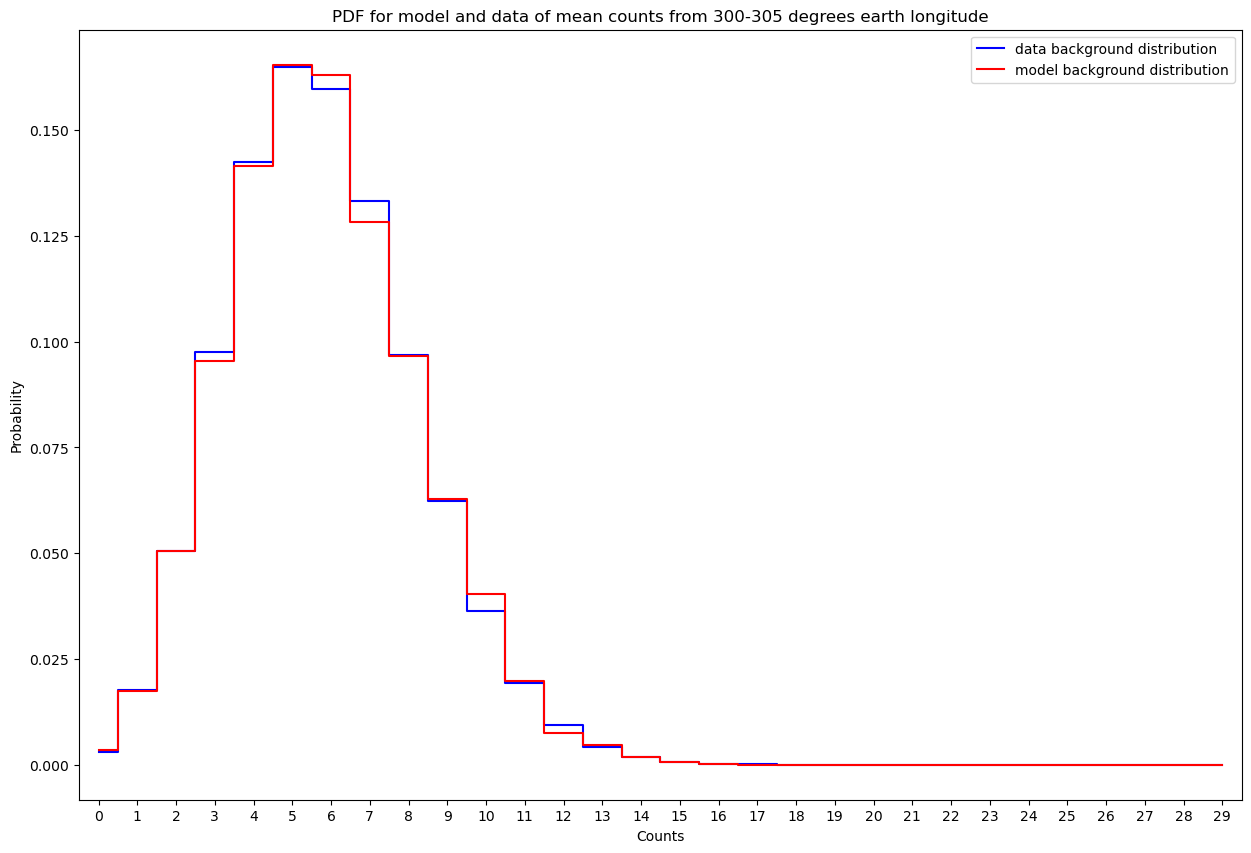

In [264]:
# Histogram of data for same orbital degree ( first 300 to 305 degrees)

lon_start = 300
lon_end = 305

earth_longitude = data[2]
counts = data[3]

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

fig, ax = plt.subplots(1, 1)
ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='blue',
    label='data background distribution'
)

ax.set_xticks(count_list)
ax.set_xlim(-0.5, len(count_list) - 0.5)
ax.set_xlabel('Counts')
ax.set_ylabel('Probability')


# Histogram of model data for same orbital degree ( first 300 to 305 degrees)

lon_start = 300
lon_end = 305

earth_longitude = data_model[2]
counts = data_model[1]

print(data_model[1])

mask = (earth_longitude >= lon_start) & (earth_longitude <= lon_end)

selected_counts = counts[mask]

count_list = np.arange(0, 30)

num_count_val = np.bincount(selected_counts.astype(int), minlength=30)[:30]
prob_num_counts = num_count_val / len(selected_counts)

ax.step(
    count_list,
    prob_num_counts,
    where='mid',
    linewidth=1.5,
    color='red',
    label='model background distribution'
)

ax.legend(loc='upper right')
ax.set_title('PDF for model and data of mean counts from 300-305 degrees earth longitude')

plt.show()


#### Response for 3)
The plot above shows the model background is not terribly far off, and considering the parameters for the exponential decay of the mean background count per .1 s period were estimated from plots, then improvements to the model could improve how well the model fits the actual apparent background. Also, because of finite sampling from real data and model data, the actual pdf of the background for both may differ from what is shown, especially for the model data if 5 degrees over 20 periods is not sufficient.

4. Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?


In [268]:
# Code for 4)

# time at start of orbital period, 45 degrees (about 270 deg before reset of exponential)
time = data_model[0][0]
prob_5_sigma = stats.norm.sf(5, loc=0, scale=1)

phase = ((((time - data[0][0])* 360 / (60*90) + data[2][0])  % 360)) # converting to phase, time or orbital period could also be used
mu = 5.7 + 5.6 * np.e**(-.01100 * ((phase - 315.15) % 360)) # value of .0150 estimated based on 1/2 exponential value being at around 65 degrees
counts_5_sig = stats.poisson.isf(prob_5_sigma, mu=mu, loc=0)

print(f"needed number of counts for threshold of 5 sigma are: {counts_5_sig} counts at time {time} in gps seconds")

# time a little after reset (320 degrees about)
t_idx = int(90*60*10 * (270 / 360) + 90*60*10*5/360)
time = data_model[0][t_idx]
phase = ((((time - data[0][0])* 360 / (60*90) + data[2][0])  % 360)) # converting to phase, time or orbital period could also be used
mu = 5.7 + 5.6 * np.e**(-.01100 * ((phase - 315.15) % 360)) # value of .0150 estimated based on 1/2 exponential value being at around 65 degrees

counts_5_sig = stats.poisson.isf(prob_5_sigma, mu=mu, loc=0)

print(f"needed number of counts for threshold of 5 sigma are: {counts_5_sig} counts at time {time} in gps seconds")

# before exponential, about 300
t_idx = int(90*60*10 * (270 / 360) - 90*60*10*15/360)
time = data_model[0][t_idx]
phase = ((((time - data[0][0])* 360 / (60*90) + data[2][0])  % 360)) # converting to phase, time or orbital period could also be used
mu = 5.7 + 5.6 * np.e**(-.01100 * ((phase - 315.15) % 360)) # value of .0150 estimated based on 1/2 exponential value being at around 65 degrees

counts_5_sig = stats.poisson.isf(prob_5_sigma, mu=mu, loc=0)

print(f"needed number of counts for threshold of 5 sigma are: {counts_5_sig} counts at time {time} in gps seconds")

needed number of counts for threshold of 5 sigma are: 25.0 counts at time 940680016.0 in gps seconds
needed number of counts for threshold of 5 sigma are: 31.0 counts at time 940684141.0038195 in gps seconds
needed number of counts for threshold of 5 sigma are: 21.0 counts at time 940683841.0035417 in gps seconds


5) While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

#### Answer to 5)

The background appears to be well described by a model of a poisson distribution with a constant mean count rate plus a exponentially decaying rate that resets with each orbital period. The constant mean rate could be from sources outside the immediate vicinity of the earth, while the exponentially decaying mean rate contribution appears to be associated with particular latitudes of earth. Perhaps as the telescope passes a specific region of its orbit, such as through the SAA (South Atlantic Anomaly), the increased radiation and charged particles induce nuclear decay that produces heightened gamma ray counts. Once the satellite passes through the region, the nuclear decay continues with some halflife extending the increased rate of gamma ray counts for tens of minutes as the orbit continues before settling down to a mean gamma ray detection count. This baseline count could be due to background gamma rays not from gamma ray bursts, as well as from interactions of the matter in the atmosphere and the satellite itself that produces gamma rays either directly or indirectly leading to detection and counts.